In [13]:
# wavelength interpolation

import dLux as dl
import jax.numpy as np
import jax
import matplotlib.pyplot as plt
import dLux.utils as dlu
from dLux.sources import Source
from jax import Array
from dLux.sources import BaseSource
from jax import vmap
import jax.random as jr
from dLux import spectra
jax.config.update("jax_enable_x64", True)
plt.rcParams['image.origin'] = 'lower'

from jax.scipy.special import gammaln, xlogy

def poisson_loglike_gamma(k, mu):
    # analytic continuation using gammaln(k+1)
    k = np.asarray(k, dtype=float)
    mu = np.asarray(mu, dtype=float)
    valid = (k >= 0) & np.isfinite(k) & (mu > 0) & np.isfinite(mu)
    logp = xlogy(k, mu) - mu - gammaln(k + 1.0)
    return np.where(valid, logp, -np.inf)

# define the likelihood function:
def poiss_loglike(pytree, data) -> float:
    """
    Poissonian log likelihood of the pytree given the data. Assumes the pytree
    has a .model() function.

    Parameters
    ----------
    pytree : Base
        Pytree with a .model() function.
    data : Array
        Data to compare the model to.

    Returns
    -------
    log_likelihood : Array
        Log likelihood of the pytree given the data.
    """
    return poisson_loglike_gamma(pytree.model(), data).sum()

def normal_logpdf(x, mu, sigma):
    z = (x-mu)/sigma
    return -0.5 * (np.log(2*np.pi) + 2*np.log(sigma) + z**2)

In [14]:
eps = 1e-15
class CombinedSpectrum(dl.Spectrum):
    wavelengths: Array
    filt_weights: Array
    basis_weights: Array
    weights: Array
    flux: float

    def __init__(self, wavels, filt_weights, basis_weights):
        self.wavelengths = np.asarray(wavels, dtype=float)
        self.filt_weights = np.asarray(filt_weights, dtype=float)
        self.basis_weights = np.asarray(basis_weights, dtype=float)

        spec_w = self.spec_weights()
        weights = self.filt_weights * spec_w
        self.weights = weights / weights.sum()
        self.flux = np.sum(spec_w)

    def spec_weights(self):
        raise NotImplementedError

    def normalise(self):
        return self


class CombinedBasisSpectrum(CombinedSpectrum):
    basis_vects: Array

    def __init__(self, wavels, filt_weights, basis_weights, basis):
        self.basis_vects = np.asarray(basis, dtype=float)
        super().__init__(wavels, filt_weights, basis_weights)

    def spec_weights(self):
        return np.maximum(np.sum(self.basis_vects * self.basis_weights, axis=1), eps)
        # return 10 ** (np.sum(self.basis_vects * self.basis_weights, axis=1))

In [15]:
wf_npixels = 128
diameter = 1.0
wf_oversample = 5

# changing
n_wavels_data = 101
psf_npixels = 20 # 10-100 lambda/D

coords = dlu.pixel_coords(wf_npixels*wf_oversample, diameter)

primary = dlu.circle(coords, diameter/2)

aperture = dlu.combine(np.array([primary]), wf_oversample)

aperture_layer = dl.TransmissiveLayer(aperture, True)

layers = [
    (
        'aperture',
        aperture_layer
    )
]


psf_pixel_scale = dlu.rad2arcsec((1.0e-6)/2) # nyquist
oversample = 2 # double oversample nyquist

optics = dl.AngularOpticalSystem(
    wf_npixels=wf_npixels,
    diameter=diameter,
    layers=layers,
    psf_npixels=psf_npixels,
    psf_pixel_scale=psf_pixel_scale,
    oversample=oversample
)


wlmin_data = 1.0e-6
wlmax_data = 2.0e-6

wavelengths_data = np.linspace((wlmin_data), (wlmax_data), n_wavels_data)

wlmin_data = np.min(wavelengths_data)
wlmax_data = np.max(wavelengths_data)

log_flux_data = 6 # billion photons?

nbasis = n_wavels_data

bandpass = np.ones(n_wavels_data)

spectrum_bins = CombinedBasisSpectrum(wavelengths_data, bandpass, np.ones(nbasis), np.eye(nbasis))

source_data = dl.PointSource(
    spectrum=spectrum_bins
)


model_data = dl.Telescope(optics, source_data)

def model_psf(spectrum, instrument):
    old_spec = instrument.get("source.spectrum")

    new_spec = CombinedBasisSpectrum(
        wavels=old_spec.wavelengths,
        filt_weights=old_spec.filt_weights,
        basis_weights=spectrum,
        basis=old_spec.basis_vects,
    )

    telescope = instrument.set("source.spectrum", new_spec)
    telescope = telescope.set("source.flux", telescope.get("source.spectrum").flux)
    return telescope.model()
    
injected_spectrum = np.ones(n_wavels_data)/n_wavels_data * 10**log_flux_data

# plt.plot(injected_spectrum)
img_full = model_psf(injected_spectrum, model_data)
#data = jr.poisson(jr.PRNGKey(0), img_full)

In [16]:
from zodiax.diffops import hessian
import jax.scipy as jsp

def loss_fn(params, model, data):
    spectrum = params['spectrum']
    img = model_psf(spectrum, model)
    loss = -poisson_loglike_gamma(data, img).sum()
    return loss

params = {
    "spectrum": injected_spectrum
}

# let us do preconditioning with the data... this is fine because we are somewhat close to maximum likelihood
# since we can just do a flat spectrum with the same total flux

# upon later consideration.. don't do wrt. data because you get strange eigval trends

# upon even later consideration... DO do wrt. data. trust.
f = lambda params: loss_fn(params, model_data, img_full)

H, unflatten = hessian(f, params)

H = 0.5 * (H + H.T) # symmetretise

In [17]:
# Now take appropriate eigvecs and vals

eigvals, eigvecs = np.linalg.eigh(H)

idx = np.argsort(eigvals)[::-1]

eigvals = eigvals[idx]
eigvecs = eigvecs[:, idx]
mode_spectra = np.fft.rfft(eigvecs, axis=0)

In [19]:
# the best metric I've found is quadratic variation in the slope/gradients

def tv_gradients(eigvecs):
    """
    total variation in gradients

    eigvecs: shape (n_wavelengths, n_modes)
    """

    q = np.asarray(eigvecs, dtype=float)

    # first differences: Δq_i,m
    dq = q[1:, :] - q[:-1, :]

    # variation of gradients:
    # Δq_i,m - Δq_i,m-1
    ddq = dq[1:, :] - dq[:-1, :]

    tvgrad = np.sum(np.abs(ddq), axis=0)

    return tvgrad

tvgrads = tv_gradients(eigvecs)
differences = tvgrads[1:] - tvgrads[:-1]
last_mode_index = np.argmax(differences)

print(f'last mode index: {last_mode_index}')
print(f'no. non-pathological modes: {last_mode_index+1}')

def tv_modes(eigvecs):

    q = np.asarray(eigvecs, dtype=float)

    total_variation = np.sum(np.abs(np.diff(q, axis=0)), axis=0)

    return total_variation

total_variation = tv_modes(eigvecs)

last mode index: 16
no. non-pathological modes: 17


In [20]:
import jax.numpy as np
import matplotlib.pyplot as plt


def persistent_jump_components(T, min_left=2, min_right=2):
    """
    Components of the persistent jump score.

    T_i is usually gradient TV for mode i.

    Returns arrays indexed by candidate split i, i.e. the jump from i to i+1.
    """

    T = np.asarray(T, dtype=float)
    n = T.shape[0]

    csum = np.cumsum(T)
    total = csum[-1]

    i = np.arange(n - 1)

    # 1. local difference: T[i+1] - T[i]
    dT = T[1:] - T[:-1]
    dT_pos = np.maximum(dT, 0.0)

    # 2. mean before/including index i
    left_count = i + 1
    left_mean = csum[:-1] / left_count

    # 3. mean after index i
    right_count = n - i - 1
    right_mean = (total - csum[:-1]) / right_count

    # 4. persistent regime contrast
    mean_diff = right_mean - left_mean
    mean_diff_pos = np.maximum(mean_diff, 0.0)

    # 5. combined persistent jump score
    score = dT_pos * mean_diff_pos

    valid = (left_count >= min_left) & (right_count >= min_right)

    dT = np.where(valid, dT, np.nan)
    dT_pos = np.where(valid, dT_pos, np.nan)
    left_mean = np.where(valid, left_mean, np.nan)
    right_mean = np.where(valid, right_mean, np.nan)
    mean_diff = np.where(valid, mean_diff, np.nan)
    mean_diff_pos = np.where(valid, mean_diff_pos, np.nan)
    score = np.where(valid, score, np.nan)

    return {
        "index": i,
        "dT": dT,
        "dT_pos": dT_pos,
        "left_mean": left_mean,
        "right_mean": right_mean,
        "mean_diff": mean_diff,
        "mean_diff_pos": mean_diff_pos,
        "score": score,
    }


def normalise_for_plot(y):
    y = np.asarray(y, dtype=float)
    ymin = np.nanmin(y)
    ymax = np.nanmax(y)

    if ymax == ymin:
        return y * np.nan

    return (y - ymin) / (ymax - ymin)

In [21]:
def eigenvalue_second_difference(eigvals, use_log=True, eps=1e-30):
    """
    Compute first and second finite differences of eigenvalues.

    Parameters
    ----------
    eigvals : array-like
        Eigenvalues ordered by mode index.
    use_log : bool
        If True, compute differences of log eigenvalues.
        Usually better for scree plots.
    eps : float
        Small positive value to avoid log(0).

    Returns
    -------
    x : ndarray
        Indices corresponding to the second difference.
    y : ndarray
        Values being differenced, either eigvals or log(eigvals).
    dy : ndarray
        First differences.
    d2y : ndarray
        Second differences.
    knee_index : int
        Index of largest positive curvature.
    """

    eigvals = np.asarray(eigvals, dtype=float)

    if use_log:
        y = np.log(eigvals + eps)
    else:
        y = eigvals

    dy = y[1:] - y[:-1]

    d2y = dy[1:] - dy[:-1]
    # equivalent to y[2:] - 2*y[1:-1] + y[:-2]

    # d2y[j] corresponds to original index j+1
    x = np.arange(1, len(eigvals) - 1)

    knee_index = x[np.nanargmax(d2y)]

    return x, y, dy, d2y, knee_index

x, y, dy, d2y, knee = eigenvalue_second_difference(eigvals, use_log=True)

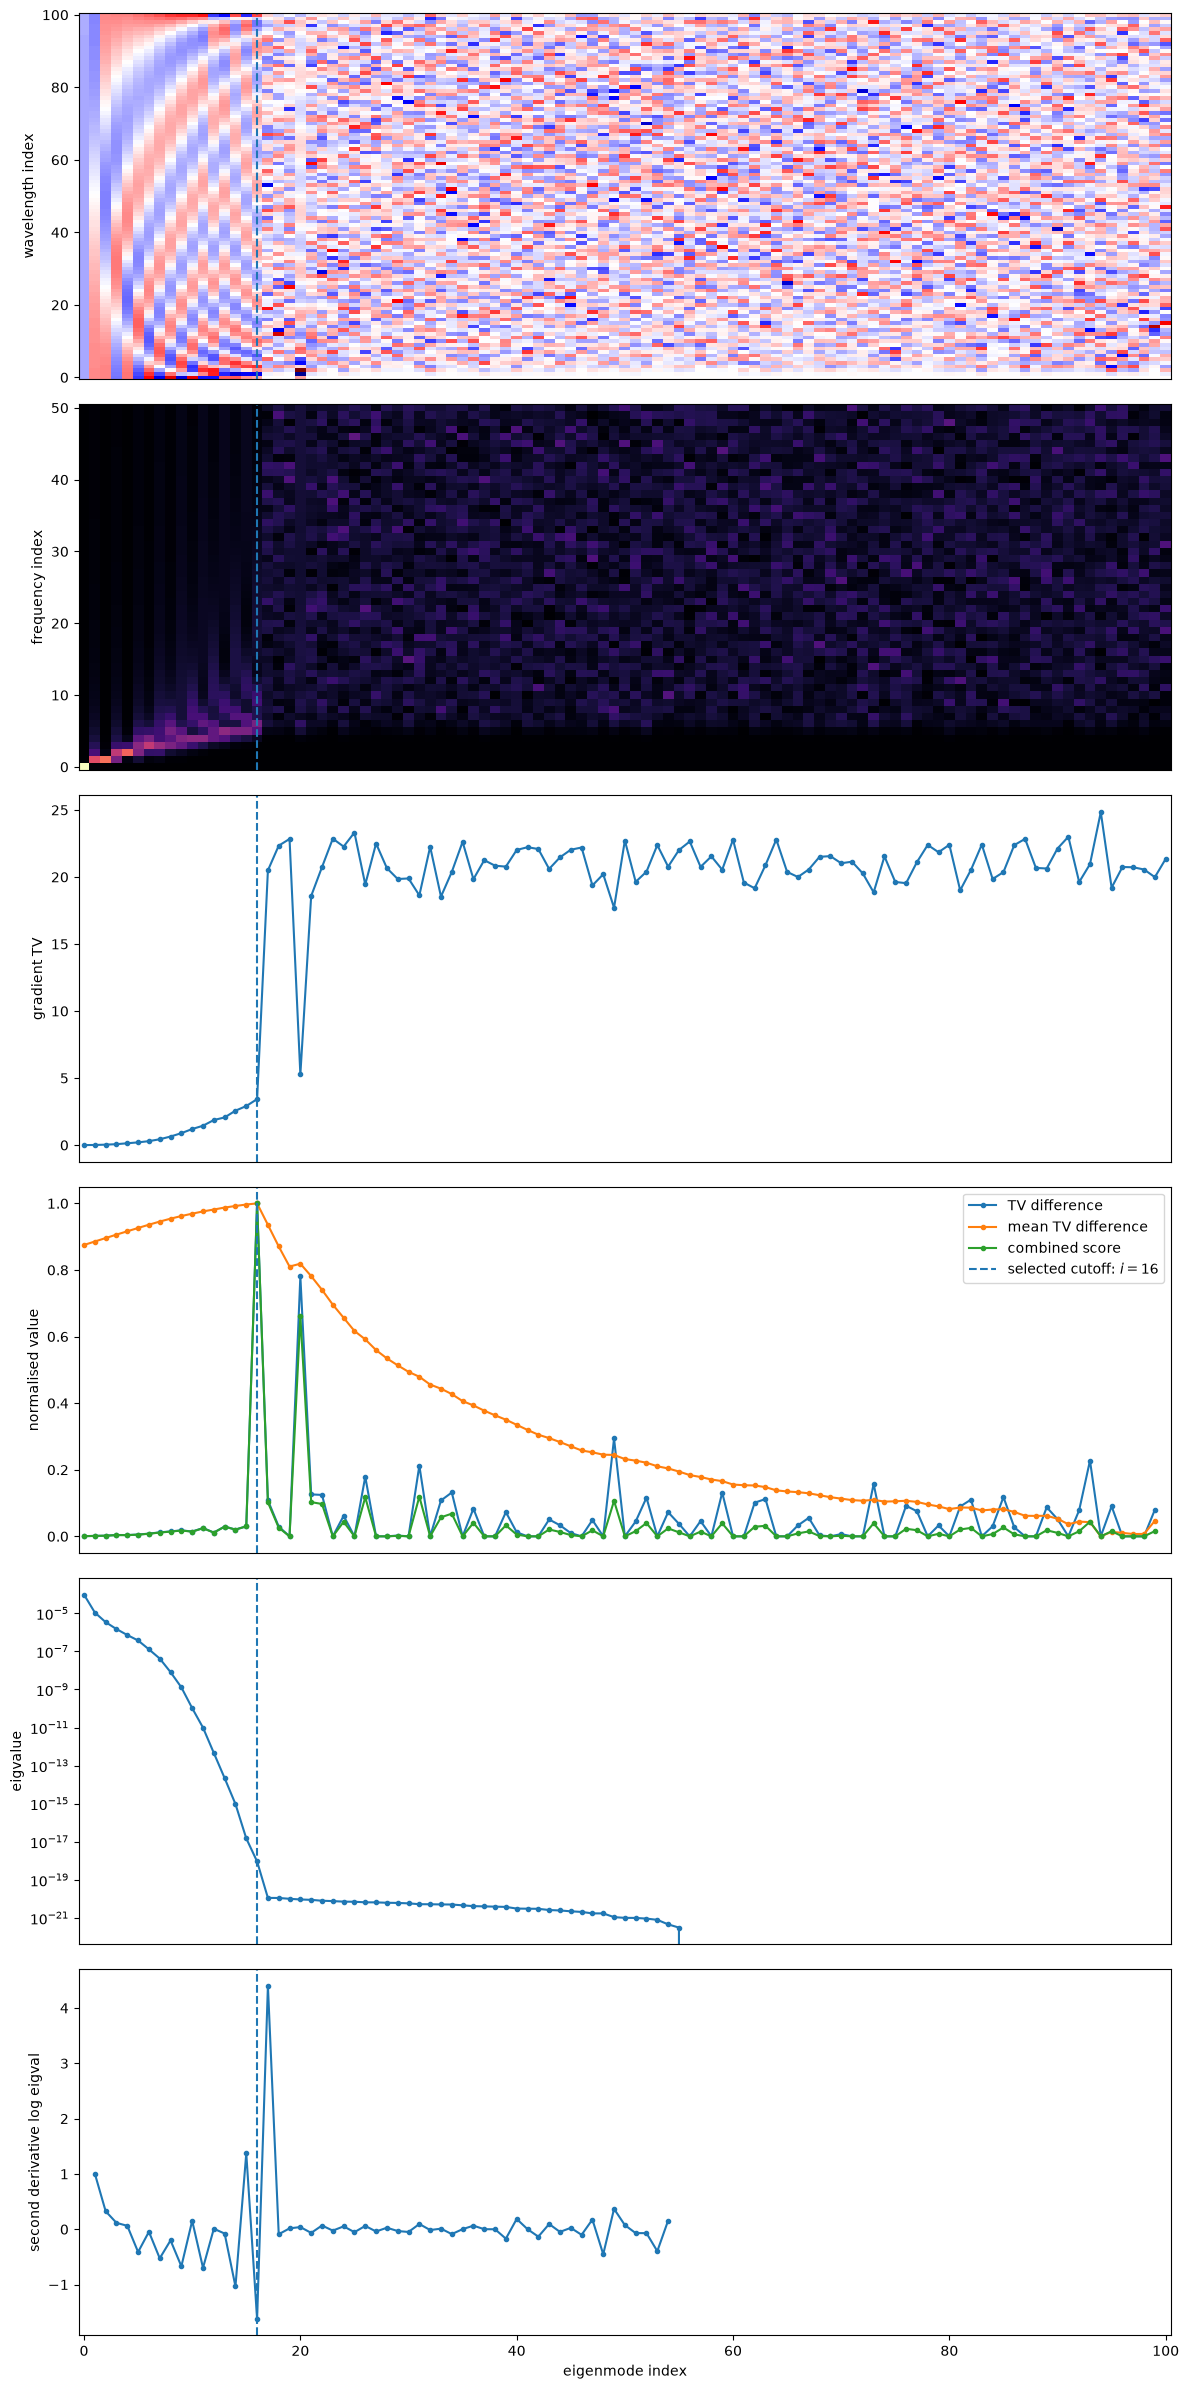

In [22]:
components = persistent_jump_components(tvgrads, min_left=0, min_right=0)

idx = np.asarray(components["index"])

dT_plot = normalise_for_plot(components["dT_pos"])
mean_diff_plot = normalise_for_plot(components["mean_diff_pos"])
score_plot = normalise_for_plot(components["score"])

i_star = int(idx[np.nanargmax(components["score"])])

plt.figure(figsize=(12, 24))
plt.subplot(6,1,1)
v = np.max(np.abs(eigvecs))
plt.imshow(eigvecs, interpolation='none', vmax=v,vmin=-v, cmap='seismic', aspect="auto")
plt.xticks([])
plt.ylabel('wavelength index')
plt.axvline(i_star, ls="--")
# plt.colorbar()

plt.subplot(6,1,2)
plt.imshow(np.abs(mode_spectra), interpolation='none', cmap='magma', aspect="auto")
plt.xticks([])
plt.ylabel('frequency index')
plt.axvline(i_star, ls='--')

plt.subplot(6,1,3)
plt.plot(tvgrads, '.-')
plt.xticks([])
plt.xlim(-0.5, n_wavels_data-0.5)
plt.axvline(i_star, ls='--')
plt.ylabel('gradient TV')

plt.subplot(6,1,4)
plt.plot(idx, dT_plot, ".-", label=r"TV difference")
plt.plot(idx, mean_diff_plot, ".-", label=r"mean TV difference")
plt.plot(idx, score_plot, ".-", label=r"combined score")

plt.axvline(i_star, ls="--", label=fr"selected cutoff: $i={i_star}$")
plt.xlim(-0.5,n_wavels_data-0.5)
plt.xticks([])

plt.ylabel("normalised value")
# plt.title("Persistent jump score components")
plt.legend(loc='upper right')

plt.subplot(6,1,5)
plt.semilogy(eigvals, ".-")
plt.axvline(knee-1, ls="--")

plt.ylabel(r"eigvalue")
# plt.title("Eigenvalue scree plot")
plt.xlim(-0.5, n_wavels_data-0.5)
plt.xticks([])


# print("Knee index:", knee)

plt.subplot(6,1,6)
plt.plot(x, d2y, ".-")
plt.axvline(knee-1, ls="--")

plt.ylabel(r"second derivative log eigval")
# plt.title("Second difference of log eigenvalues")
plt.xlim(-0.5, n_wavels_data-0.5)
plt.xlabel("eigenmode index")


plt.tight_layout()
plt.show()

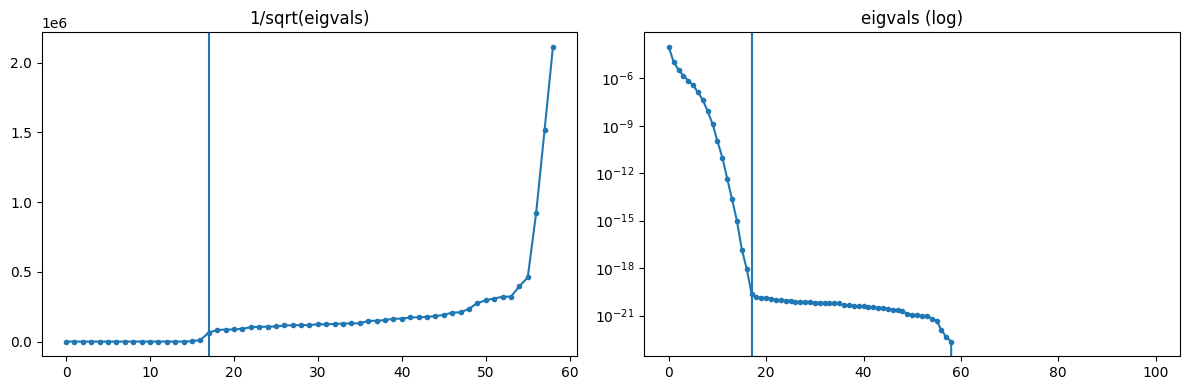

In [10]:
a = eigvecs.T @ injected_spectrum

plt.figure(figsize=(12,4))

plt.subplot(1,2,1)
plt.title('1/sqrt(eigvals)')
plt.plot(1/(np.abs(a[0]) * np.sqrt(eigvals)), '.-')
plt.axvline(i_star+1)
# plt.show()

plt.subplot(1,2,2)
plt.title('eigvals (log)')
plt.semilogy(eigvals, '.-')
plt.axvline(i_star+1)

plt.tight_layout()
plt.show()

8


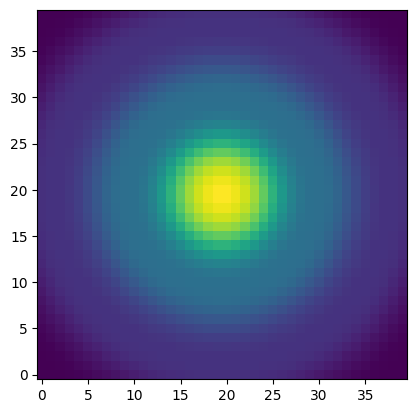

In [11]:
relstd = 1/(np.abs(a[0]) * np.sqrt(eigvals))
print(np.argmax(relstd>0.1))
plt.imshow(np.log10(img_full))

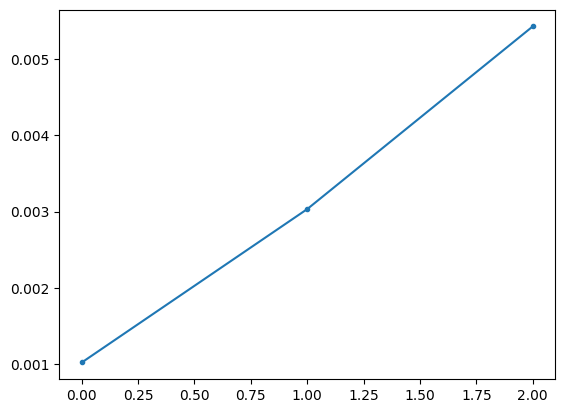

In [12]:
plt.plot(1/(np.abs(a[0]) * np.sqrt(eigvals))[:3], '.-')
# plt.axvline(last_mode_index+1)

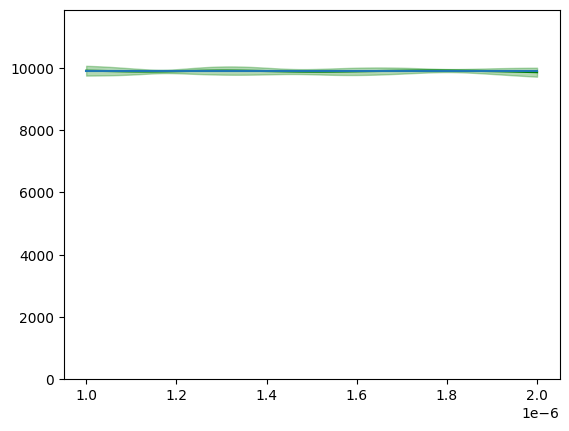

In [13]:
### let us plot the spectrum upto a certain number of modes:

nmodes_plot = 4
spec_mean = eigvecs[:,:nmodes_plot] @ a[:nmodes_plot]
spec_var = (eigvecs[:,:nmodes_plot]**2) @ (1/(eigvals[:nmodes_plot]))
spec_std = np.sqrt(spec_var)

plt.plot(
    wavelengths_data,
    spec_mean,
    color='green',
    label=f'recovered spectrum, nmodes={nmodes_plot}'
)
plt.fill_between(
    wavelengths_data,
    spec_mean - spec_std,
    spec_mean + spec_std,
    color='green',
    alpha=0.3
)
plt.ylim(0, 1.2*np.max(injected_spectrum))

plt.plot(wavelengths_data, injected_spectrum)

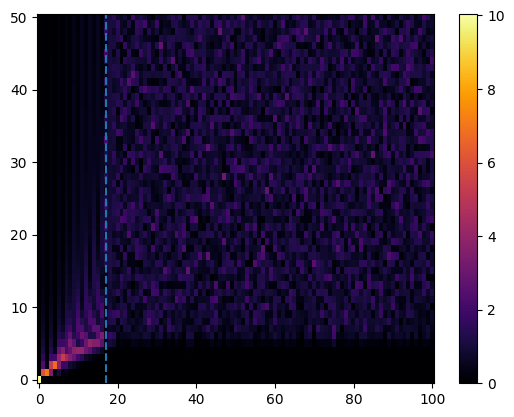

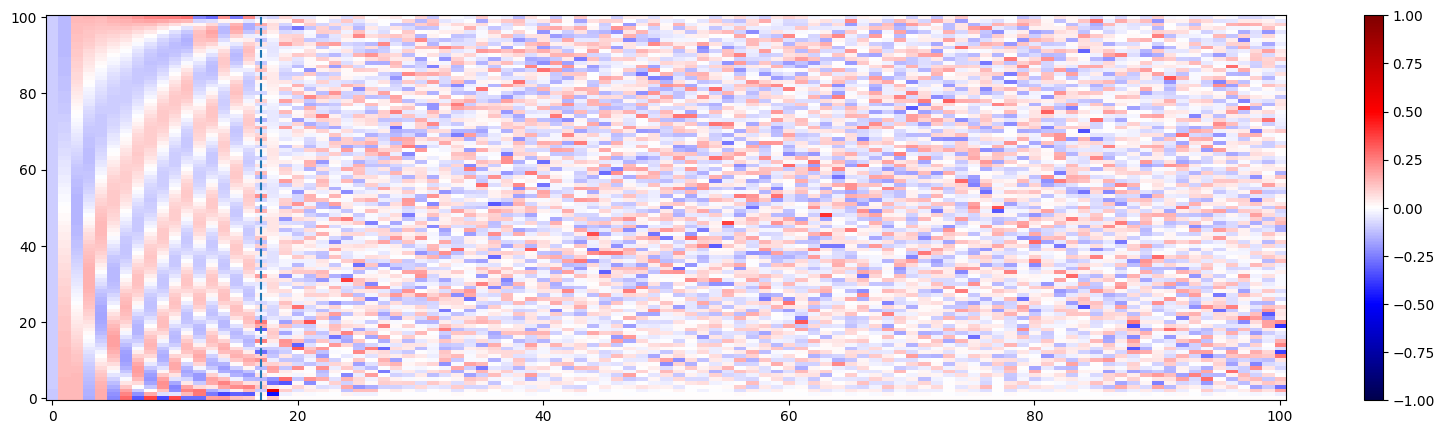

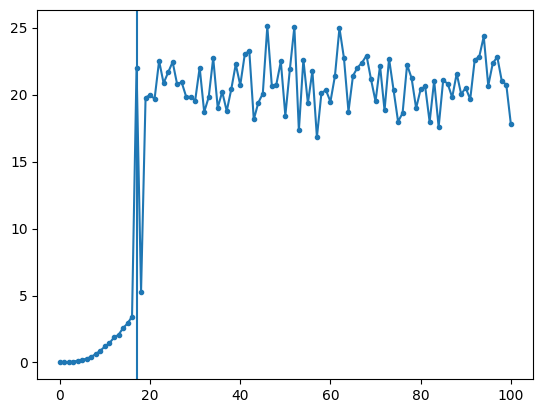

last mode index: 16
no. constrained modes: 17


In [14]:
plt.imshow((np.abs(mode_spectra[:,:])), cmap='inferno', aspect='auto', interpolation='none')
plt.axvline(last_mode_index+1, ls='--')
plt.colorbar()
plt.show()

plt.figure(figsize=(20,5))
plt.imshow(eigvecs[:,:], cmap='seismic', aspect='auto', interpolation='none', vmax=1,vmin=-1)
plt.axvline(last_mode_index+1, ls='--')
plt.colorbar()
plt.show()

plt.plot(tvgrads[:], ".-")
plt.axvline(last_mode_index+1)
plt.show()

# plt.plot(total_variation[:], ".-")
# plt.show()

print(f'last mode index: {last_mode_index}')
print(f'no. constrained modes: {last_mode_index+1}')

Last non-pathological mode index: 16
First pathological mode index: 17


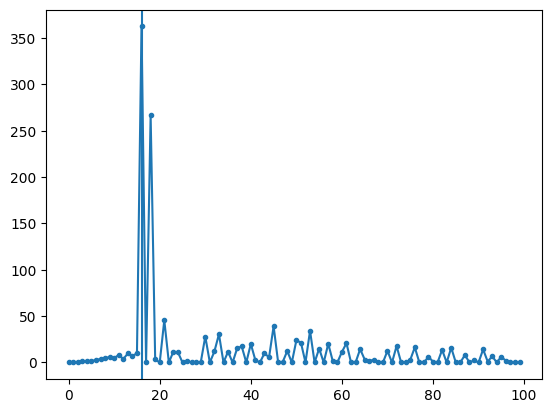

In [15]:
# import jax.numpy as np

def persistent_jump_score(T, min_left=1, min_right=1, eps=1e-30):
    """
    Finds a large positive local jump that also corresponds to a persistent
    change in the mean level of the sequence.

    T : array, shape (n_modes,)
        Roughness metric, e.g. TV_grad(q_i).
    """

    T = np.asarray(T, dtype=float)
    n = T.shape[0]

    csum = np.cumsum(T)
    total = csum[-1]

    i = np.arange(n - 1)

    # local positive jump: T[i+1] - T[i]
    dT = T[1:] - T[:-1]
    dT_pos = np.maximum(dT, 0.0)

    # mean before/including i
    left_count = i + 1
    left_mean = csum[:-1] / left_count

    # mean after i
    right_count = n - i - 1
    right_mean = (total - csum[:-1]) / right_count

    # persistent regime contrast
    regime_contrast = right_mean - left_mean
    regime_contrast_pos = np.maximum(regime_contrast, 0.0)

    score = dT_pos * regime_contrast_pos

    # Exclude splits with too few points on either side
    valid = (left_count >= min_left) & (right_count >= min_right)
    score = np.where(valid, score, -np.inf)

    i_star = np.argmax(score)

    return i_star, score, dT, regime_contrast

i_star, score, dT, regime_contrast = persistent_jump_score(tvgrads, min_right=1)

print("Last non-pathological mode index:", i_star)
print("First pathological mode index:", i_star + 1)

plt.plot(score, '.-')
plt.axvline(i_star)
plt.show()

In [16]:
def mean_split_difference(x):
    """
    For each index i, compute

        mean(x[i+1:]) - mean(x[:i+1])

    Returns NaN for the final index since there is no right-hand side.
    """

    x = np.asarray(x, dtype=float)

    n = x.shape[0]

    csum = np.cumsum(x)
    total = csum[-1]

    idx = np.arange(n)

    # left means: mean(x[:i+1])
    left_mean = csum / (idx + 1)

    # right means: mean(x[i+1:])
    right_count = n - idx - 1
    right_sum = total - csum

    right_mean = right_sum / right_count

    diff = right_mean - left_mean

    # final index has empty RHS
    diff = diff.at[-1].set(np.nan)

    return diff

means = mean_split_difference(tvgrads)

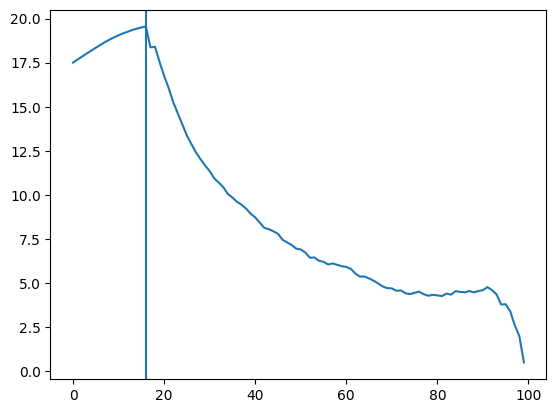

In [17]:
plt.plot(means)
plt.axvline(np.nanargmax(means))

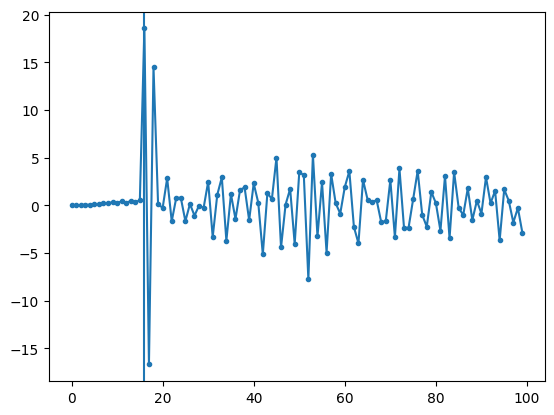

In [18]:
plt.plot(differences, '.-')
plt.axvline(16)

In [19]:
from dataclasses import dataclass
import numpy as np


@dataclass
class ScreeKneeResult:
    q: int                         # number of retained components/modes
    split_index: int               # Python split index: values[:q] | values[q:]
    knee_between: tuple[int, int]   # zero-based indices between which the knee lies
    log_likelihoods: np.ndarray    # profile log-likelihood for each candidate q
    candidate_qs: np.ndarray       # candidate q values
    means_left: np.ndarray         # fitted mean of values[:q]
    means_right: np.ndarray        # fitted mean of values[q:]
    sigma2: np.ndarray             # fitted common variance for each q


def find_scree_knee_zhu_ghodsi(
    values,
    *,
    sort_descending: bool = True,
    transform: str | None = None,
    min_size: int = 1,
    eps: float = 1e-300,
) -> ScreeKneeResult:
    """
    Find the knee/elbow in a scree plot using the Zhu & Ghodsi profile-likelihood method.

    Parameters
    ----------
    values : array-like, shape (p,)
        Ordered importance values, e.g. eigenvalues, singular values, Fisher eigenvalues,
        mode amplitudes, etc. The knee q means retain values[:q].

    sort_descending : bool
        If True, sort values in descending order before applying the method.

    transform : {None, "log"}
        If "log", apply log(values) before fitting the two-Gaussian model.
        This is sometimes useful for rapidly decaying scree plots.

    min_size : int
        Minimum number of points allowed on each side of the split.
        The original algorithm effectively allows min_size=1.
        Use min_size=2 if you want both sides to contain at least two points.

    eps : float
        Small floor used to avoid log(0) when the residual variance is numerically zero.

    Returns
    -------
    ScreeKneeResult
        q is the number of retained components. The knee is between values[q-1] and values[q].

    Notes
    -----
    For each candidate q, the model is

        values[:q] ~ N(mu_1, sigma^2)
        values[q:] ~ N(mu_2, sigma^2)

    with a shared variance. The selected q maximises the profiled Gaussian log-likelihood.
    """

    x = np.asarray(values, dtype=np.float64).ravel()

    if x.ndim != 1:
        raise ValueError("values must be one-dimensional.")

    if x.size < 3:
        raise ValueError("Need at least 3 scree values to define a meaningful knee.")

    if not np.all(np.isfinite(x)):
        raise ValueError("values contains NaN or infinite entries.")

    if sort_descending:
        x = np.sort(x)[::-1]

    if transform is not None:
        if transform != "log":
            raise ValueError("transform must be None or 'log'.")
        if np.any(x <= 0):
            raise ValueError("Log transform requires all values to be strictly positive.")
        x = np.log(x)

    p = x.size

    if min_size < 1:
        raise ValueError("min_size must be at least 1.")

    if 2 * min_size > p:
        raise ValueError("min_size is too large for the number of values.")

    # Candidate q means:
    #   left group  = x[:q]
    #   right group = x[q:]
    # so q ranges from min_size to p - min_size.
    candidate_qs = np.arange(min_size, p - min_size + 1)

    csum = np.cumsum(x)
    csum2 = np.cumsum(x * x)

    total_sum = csum[-1]
    total_sum2 = csum2[-1]

    n1 = candidate_qs.astype(np.float64)
    n2 = (p - candidate_qs).astype(np.float64)

    sum1 = csum[candidate_qs - 1]
    sumsq1 = csum2[candidate_qs - 1]

    sum2 = total_sum - sum1
    sumsq2 = total_sum2 - sumsq1

    means_left = sum1 / n1
    means_right = sum2 / n2

    # Sum of squared residuals within each fitted Gaussian group.
    # This direct formula avoids NaNs for one-point groups.
    sse1 = sumsq1 - (sum1 * sum1) / n1
    sse2 = sumsq2 - (sum2 * sum2) / n2
    sse = sse1 + sse2

    # Numerical roundoff can make SSE tiny-negative when it should be zero.
    sse = np.maximum(sse, 0.0)

    # Gaussian MLE for common variance.
    # The paper writes the usual pooled estimate with denominator p - 2;
    # using p gives the exact Gaussian MLE. The argmax over q is identical
    # either way because the denominator is constant across q.
    sigma2 = np.maximum(sse / p, eps)

    log_likelihoods = (
        -0.5 * p * (np.log(2.0 * np.pi) + 1.0 + np.log(sigma2))
    )

    best = int(np.argmax(log_likelihoods))
    q = int(candidate_qs[best])

    return ScreeKneeResult(
        q=q,
        split_index=q,
        knee_between=(q - 1, q),
        log_likelihoods=log_likelihoods,
        candidate_qs=candidate_qs,
        means_left=means_left,
        means_right=means_right,
        sigma2=sigma2,
    )

In [20]:
result = find_scree_knee_zhu_ghodsi(np.log10((np.abs(eigvals))))

print(result.q)
print(result.knee_between)

14
(13, 14)


In [21]:
eigvals

Array([ 9.59401362e-05,  1.09799012e-05,  3.43491136e-06,  1.48778301e-06,
        7.23232990e-07,  3.74166180e-07,  1.28238042e-07,  4.19952784e-08,
        8.13029886e-09,  1.28704743e-09,  1.04244267e-10,  9.83798760e-12,
        4.61978859e-13,  2.18936319e-14,  9.59922601e-16,  1.49612276e-17,
        9.18397825e-19,  2.43113823e-20,  1.47713808e-20,  1.36465653e-20,
        1.35061677e-20,  1.19525479e-20,  9.52417465e-21,  9.03015930e-21,
        8.85788332e-21,  8.63429428e-21,  7.61287275e-21,  7.31866965e-21,
        7.27495281e-21,  7.19105103e-21,  6.62179304e-21,  6.54288713e-21,
        6.37660581e-21,  6.06208497e-21,  5.92319482e-21,  5.92285099e-21,
        4.60451778e-21,  4.51717104e-21,  4.28285072e-21,  3.76959609e-21,
        3.73523582e-21,  3.38047213e-21,  3.34347516e-21,  3.21472949e-21,
        3.04450938e-21,  2.74819994e-21,  2.33831861e-21,  2.30552055e-21,
        1.82582877e-21,  1.32700135e-21,  1.15041555e-21,  1.05943560e-21,
        9.78719056e-22,  

In [22]:
result

ScreeKneeResult(q=14, split_index=14, knee_between=(13, 14), log_likelihoods=array([-288.96345742, -283.31899736, -277.32386186, -270.76909989,
       -263.45880934, -255.13216415, -245.75621587, -235.01721713,
       -223.01066422, -209.68666382, -196.17176797, -183.0989925 ,
       -174.14257973, -171.85378528, -176.89220875, -189.12414133,
       -201.95458446, -215.08866736, -224.56357256, -232.14184664,
       -238.15247832, -243.08067329, -247.19762726, -250.69597272,
       -253.73081462, -256.40071871, -258.77977017, -260.91822256,
       -262.83086574, -264.56258874, -266.1296712 , -267.56402877,
       -268.87731543, -270.08598482, -271.20152663, -272.23431   ,
       -273.19197953, -274.10086563, -274.94989126, -275.74305049,
       -276.48624324, -277.18389895, -277.8437473 , -278.46583675,
       -279.05411706, -279.61761578, -280.15376217, -280.66318304,
       -281.14957774, -281.61517816, -282.05891007, -282.48268757,
       -282.88912856, -283.27685489, -283.65365355, 

In [23]:
logeigvalgrads = np.log10(eigvals)[1:] - np.log10(eigvals)[:-1]

/var/folders/2s/299fsjvd5w13x4x_w7x554fh0000gn/T/ipykernel_69567/1179217589.py:1: RuntimeWarning: invalid value encountered in log10
  logeigvalgrads = np.log10(eigvals)[1:] - np.log10(eigvals)[:-1]


/var/folders/2s/299fsjvd5w13x4x_w7x554fh0000gn/T/ipykernel_69567/3906863274.py:1: RuntimeWarning: invalid value encountered in log10
  plt.plot(np.log10(eigvals))


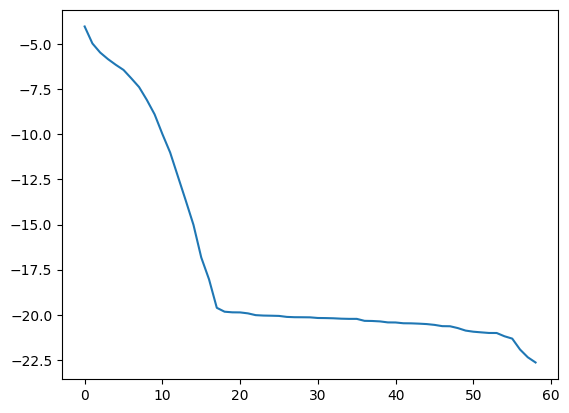

In [24]:
plt.plot(np.log10(eigvals))

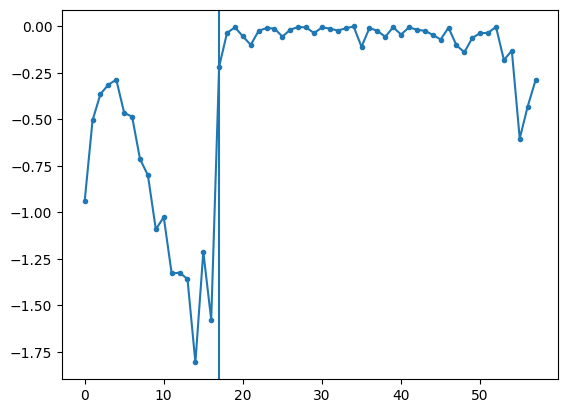

In [25]:
plt.plot(logeigvalgrads, '.-')
plt.axvline(np.nanargmax(np.abs(logeigvalgrads[1:] - logeigvalgrads[:-1]))+1)

In [38]:
from pysr import PySRRegressor

In [39]:
# First 10 eigenvectors
Y = eigvecs[:, :10]  # shape: (N_lambda, 10)

# Eigenvector indices
N = np.arange(10)

# Make meshgrid of wavelengths and eigenvector indices
lam = wavelengths_data
lam_scaled = (lam - lam.mean()) / lam.std()

L_grid, N_grid = np.meshgrid(lam_scaled, N, indexing="ij")

# Flatten into PySR input format
X = np.column_stack([
    L_grid.ravel(),
    N_grid.ravel(),
])

y = Y.ravel()

print(X.shape)  # (N_lambda * 10, 2)
print(y.shape)  # (N_lambda * 10,)

(1010, 2)
(1010,)


In [40]:
modelPySR = PySRRegressor(
    maxsize=20,
    niterations=200,
    binary_operators=["+", "-", "*", "/"],
    unary_operators=["cos", "sin", "exp", "log"],
    variable_names=["x", "n"],
    elementwise_loss="loss(prediction, target) = (prediction - target)^2",
)

modelPySR.fit(X, y)

/Users/milolangker/anaconda3/envs/abcdLuxEditEnv/lib/python3.12/site-packages/pysr/sr.py:1046: FutureWarning: `variable_names` is a data-dependent parameter and should be passed when fit is called. Ignoring parameter; please pass `variable_names` during the call to fit instead.
  warnings.warn(
/Users/milolangker/anaconda3/envs/abcdLuxEditEnv/lib/python3.12/site-packages/pysr/sr.py:2811: UserWarning: Note: it looks like you are running in Jupyter. The progress bar will be turned off.
  warnings.warn(
[ Info: Started!



Expressions evaluated per second: 2.190e+05
Progress: 1335 / 6200 total iterations (21.532%)
════════════════════════════════════════════════════════════════════════════════════════════════════
───────────────────────────────────────────────────────────────────────────────────────────────────
Complexity  Loss       Score      Equation
1           9.800e-03  0.000e+00  y = -0.010051
4           9.037e-03  2.702e-02  y = -0.086418 / exp(x₁)
5           8.912e-03  1.397e-02  y = -0.0033521 / (x₁ + 0.033625)
6           8.911e-03  1.184e-04  y = exp(x₁ / -0.23294) * -0.099468
8           6.668e-03  1.450e-01  y = cos(x₁ * (x₀ - 0.74534)) * -0.076829
10          6.559e-03  8.206e-03  y = cos(((x₀ - 0.65998) / 0.94583) * x₁) * -0.078148
12          6.320e-03  1.860e-02  y = cos(x₁ * ((x₁ / (x₁ + 2.0107)) - x₀)) * -0.080875
13          6.189e-03  2.086e-02  y = cos((x₀ - sin(cos(cos(x₁ * -0.22139)))) * x₁) * -0.082...
                                      234
14          6.018e-03  2.805e-02

[ Info: Final population:
[ Info: Results saved to:


,model_selection,'best'
,binary_operators,"['+', '-', ...]"
,unary_operators,"['cos', 'sin', ...]"
,expression_spec,None
,niterations,200
,populations,31
,population_size,27
,max_evals,None
,maxsize,20
,maxdepth,None
,warmup_maxsize_by,None


  - outputs/20260527_125838_bZx2TI/hall_of_fame.csv


In [41]:
modelPySR.sympy()

cos(x0*x1/1.1763725 - 1.1011153*(x1 - x1/(x1 - 1.0848155)))*(-0.10708029)

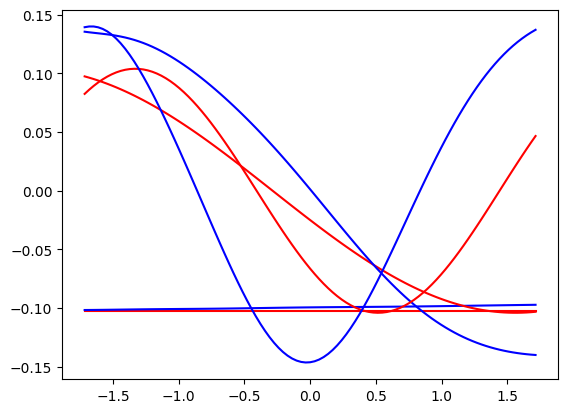

In [42]:
for i in range(3):
    plt.plot(lam_scaled, np.sin(i*(1.31 - lam_scaled)*0.85 +np.exp(2.66-i*2.08))*(-0.104), color='r')
    plt.plot(lam_scaled, eigvecs[:,i], color='b')

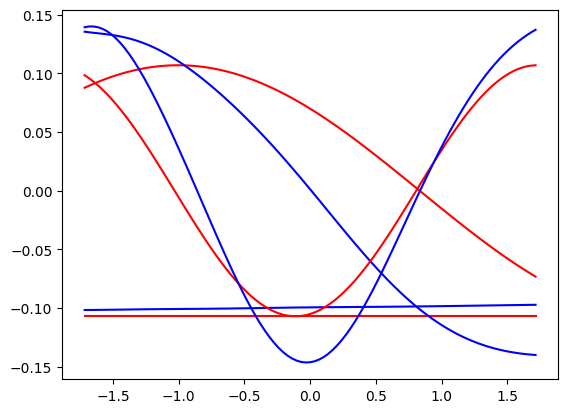

In [45]:
for i in range(3):
    plt.plot(lam_scaled, np.cos(lam_scaled*i/1.17 - (i - i/(i-1.08) )* 1.10)*(-0.107), color='r')
    plt.plot(lam_scaled, eigvecs[:,i], color='b')

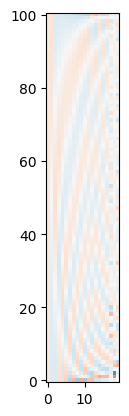

In [30]:
plt.imshow(eigvecs[:,:20],cmap='RdBu',vmin=-1,vmax=1)